<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/KMeansWithElbowMethod.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   object 
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(9), object(3)
memory 

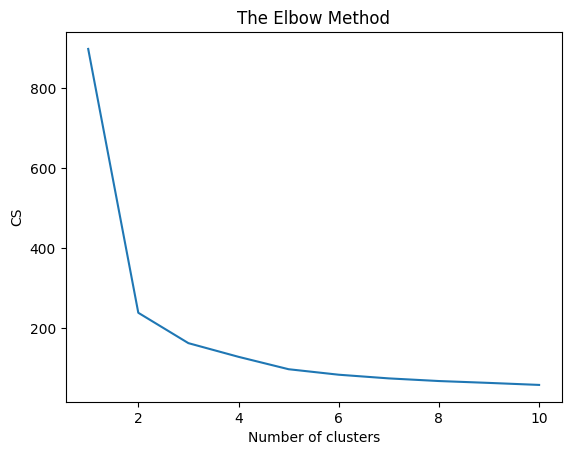

Result: 4288 out of 7050 samples were correctly labeled.
Accuracy score: 0.61


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

df = pd.read_csv("Live.csv")

df.shape
df.head()
df.info()
df.isnull().sum()

df.drop(['Column1', 'Column2', 'Column3', 'Column4'], axis=1, inplace=True)

df.info()
df.describe()
df['status_id'].unique()
len(df['status_id'].unique())

df['status_published'].unique()
len(df['status_published'].unique())

df['status_type'].unique()
len(df['status_type'].unique())

df.drop(['status_id', 'status_published'], axis=1, inplace=True)

df.info()
df.head()

X = df.copy()
y = df['status_type']

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X['status_type'] = le.fit_transform(X['status_type'])
y = le.transform(y)

X.info()
X.head()

cols = X.columns

from sklearn.preprocessing import MinMaxScaler

ms = MinMaxScaler()
X = ms.fit_transform(X)
X = pd.DataFrame(X, columns=cols)

X.head()
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(X)

kmeans.cluster_centers_

labels = kmeans.labels_

correct_labels = sum(y == labels)

print("Result: %d out of %d samples were correctly labeled." %
      (correct_labels, y.size))

print('Accuracy score: {0:0.2f}'.format(
    correct_labels / float(y.size)
))

cs = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        max_iter=300,
        n_init=10,
        random_state=0
    )
    kmeans.fit(X)
    cs.append(kmeans.inertia_)

plt.plot(range(1, 11), cs)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('CS')
plt.show()

kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(X)

labels = kmeans.labels_

correct_labels = sum(y == labels)

print("Result: %d out of %d samples were correctly labeled." %
      (correct_labels, y.size))

print('Accuracy score: {0:0.2f}'.format(
    correct_labels / float(y.size)
))